# 08 TV death curves (Sprint 8 bonus): when do long-running shows jump the shark?

- **Reads:** data/raw/ (title.episode, title.ratings, title.basics)
- **Writes:** data/processed/tv_seasons.parquet, data/processed/tv_sharks.parquet, app/data/tv_seasons_app.parquet, app/data/tv_sharks_app.parquet
- **Run after:** nothing (needs title.episode.tsv.gz in data/raw/)

What I found: 54 of 276 long-running shows jumped the shark (a drop of at least 0.5 and a fit gain of at least 0.5). Top Gear tops the list (8.15 to 5.19 from season 23), and The Simpsons dropped from 8.06 to 6.75 from season 11.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")

episodes = pd.read_csv(
    RAW / "title.episode.tsv.gz",
    sep="\t",
    na_values="\\N",
    dtype={"tconst": "string", "parentTconst": "string"},
)
episodes["seasonNumber"] = pd.to_numeric(episodes["seasonNumber"], errors="coerce")
episodes["episodeNumber"] = pd.to_numeric(episodes["episodeNumber"], errors="coerce")

print(episodes.shape)
episodes.head()

(10030795, 4)


,tconst,parentTconst,seasonNumber,episodeNumber
0,tt0031458,tt32857063,NaN,NaN
1,tt0041951,tt0041038,1.0,9.0
2,tt0042816,tt0989125,1.0,17.0
3,tt0042889,tt0989125,NaN,NaN
4,tt0043426,tt0040051,3.0,42.0


In [2]:
ratings = pd.read_csv(
    RAW / "title.ratings.tsv.gz",
    sep="\t",
    na_values="\\N",
    dtype={"tconst": "string", "averageRating": "float64", "numVotes": "int64"},
)

ep = episodes.merge(ratings, on="tconst", how="inner")
print(f"{len(episodes):,} episodes -> {len(ep):,} rated episodes")

10,030,795 episodes -> 894,951 rated episodes


In [3]:
basics = pd.read_csv(
    RAW / "title.basics.tsv.gz",
    sep="\t",
    na_values="\\N",
    usecols=["tconst", "titleType", "primaryTitle", "startYear", "endYear"],
    dtype="string",
    quoting=3,
)
shows = basics[basics["titleType"].isin(["tvSeries", "tvMiniSeries"])].copy()
del basics

shows["startYear"] = pd.to_numeric(shows["startYear"], errors="coerce")
shows["endYear"] = pd.to_numeric(shows["endYear"], errors="coerce")
shows = shows.rename(columns={"tconst": "showTconst", "primaryTitle": "showTitle"})

show_ratings = ratings.rename(columns={
    "tconst": "showTconst", "averageRating": "showRating", "numVotes": "showVotes"
})
shows = shows.merge(show_ratings, on="showTconst", how="left")

ep = ep.merge(
    shows,
    left_on="parentTconst",
    right_on="showTconst",
    how="inner",
    validate="m:1",
)
print(ep.shape)
ep.head()

(894951, 13)


,tconst,parentTconst,seasonNumber,episodeNumber,averageRating,numVotes,showTconst,titleType,showTitle,startYear,endYear,showRating,showVotes
0,tt0031458,tt32857063,NaN,NaN,6.6,18,tt32857063,tvSeries,Teatro lírico español,1969,1973,NaN,NaN
1,tt0041951,tt0041038,1.0,9.0,7.6,121,tt0041038,tvSeries,The Lone Ranger,1949,1957,7.7,3333.0
2,tt0044093,tt0959862,1.0,6.0,4.4,19,tt0959862,tvSeries,The Magnavox Theater,1950,1950,6.2,28.0
3,tt0045960,tt0044284,2.0,3.0,6.9,204,tt0044284,tvSeries,Omnibus,1952,1961,8.1,237.0
4,tt0046150,tt0341798,NaN,NaN,8.2,12,tt0341798,tvSeries,Encounter,1952,1961,6.8,57.0


In [4]:
MIN_EP_VOTES = 100
MIN_EPS_PER_SEASON = 4
MIN_SEASONS = 6
MIN_SHOW_VOTES = 25_000

good = ep[
    (ep["numVotes"] >= MIN_EP_VOTES)
    & ep["seasonNumber"].between(1, 50)
    & ep["episodeNumber"].notna()
].copy()

seasons = (
    good.groupby(["showTconst", "showTitle", "seasonNumber"], as_index=False)
        .agg(
            avg_rating=("averageRating", "mean"),
            n_eps=("tconst", "count"),
            votes=("numVotes", "sum"),
            showVotes=("showVotes", "first"),
            startYear=("startYear", "first"),
        )
)
seasons = seasons[seasons["n_eps"] >= MIN_EPS_PER_SEASON]

season_counts = seasons.groupby("showTconst")["seasonNumber"].count()
long_ids = season_counts[season_counts >= MIN_SEASONS].index

seasons_long = seasons[
    seasons["showTconst"].isin(long_ids)
    & (seasons["showVotes"] >= MIN_SHOW_VOTES)
].copy()

print(seasons_long["showTconst"].nunique(), "long-running shows")
seasons_long.head(10)

276 long-running shows


,showTconst,showTitle,seasonNumber,avg_rating,n_eps,votes,showVotes,startYear
35,tt0043208,I Love Lucy,1.0,8.022857,35,18305,31315.0,1951
36,tt0043208,I Love Lucy,2.0,8.222581,31,13689,31315.0,1951
37,tt0043208,I Love Lucy,3.0,8.164516,31,11106,31315.0,1951
38,tt0043208,I Love Lucy,4.0,8.383333,30,11545,31315.0,1951
39,tt0043208,I Love Lucy,5.0,8.334615,26,9435,31315.0,1951
40,tt0043208,I Love Lucy,6.0,8.329630,27,9420,31315.0,1951
276,tt0053502,The Flintstones,1.0,7.368966,29,10072,45364.0,1960
277,tt0053502,The Flintstones,2.0,7.462500,32,7982,45364.0,1960
278,tt0053502,The Flintstones,3.0,7.450000,28,6353,45364.0,1960
279,tt0053502,The Flintstones,4.0,7.319231,26,5686,45364.0,1960


In [5]:
def find_show(text):
    hits = shows[shows["showTitle"].str.contains(text, case=False, na=False)]
    cols = ["showTconst", "showTitle", "startYear", "endYear", "showVotes"]
    return hits.sort_values("showVotes", ascending=False)[cols].head(10)

find_show("simpsons")

,showTconst,showTitle,startYear,endYear,showVotes
4728,tt0096697,The Simpsons,1989,<NA>,475004.0
275348,tt38821667,Fortnite x the Simpsons,2025,2025,398.0
82592,tt12294152,The Simpsons: Tracey Ullman Shorts,1987,1989,372.0
203389,tt29137461,Inside the Simpsons,2023,2023,21.0
232219,tt33021890,Ultimate Simpsons Challenge,<NA>,<NA>,NaN
336716,tt6207716,Simpsonville: The Real Springfield of the Simp...,<NA>,<NA>,NaN


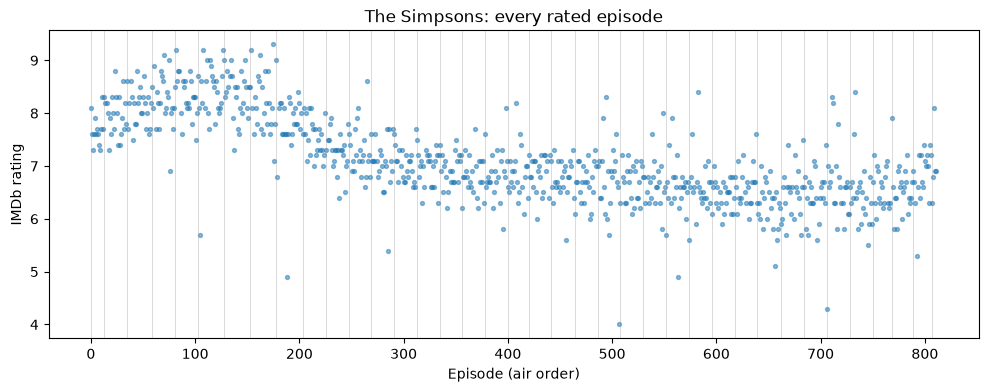

In [6]:
SHOW_ID = "tt0096697"  # paste the ID from find_show if yours differs

one = (
    good[good["showTconst"] == SHOW_ID]
    .sort_values(["seasonNumber", "episodeNumber"])
    .reset_index(drop=True)
)
one["ep_index"] = range(len(one))
title = one["showTitle"].iloc[0]

fig, ax = plt.subplots(figsize=(12, 4))
ax.scatter(one["ep_index"], one["averageRating"], s=8, alpha=0.5)
for i in one.groupby("seasonNumber")["ep_index"].min():
    ax.axvline(i, color="grey", lw=0.5, alpha=0.4)
ax.set(title=f"{title}: every rated episode",
       xlabel="Episode (air order)", ylabel="IMDb rating")
plt.show()

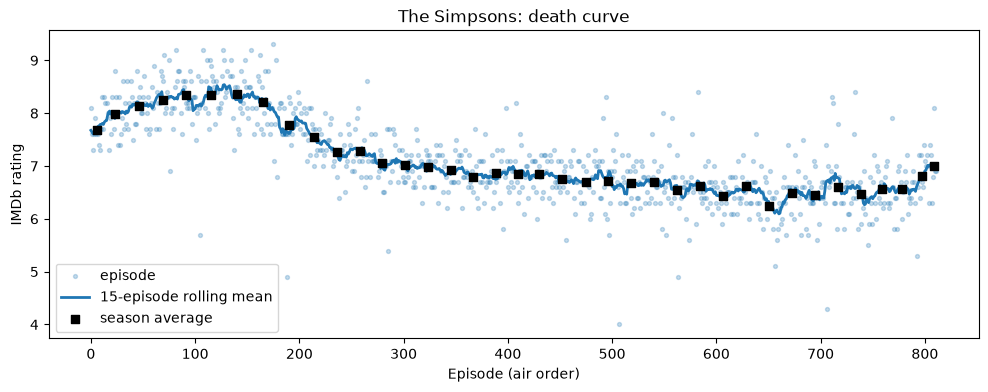

In [7]:
WINDOW = 15
one["smooth"] = (
    one["averageRating"]
    .rolling(window=WINDOW, center=True, min_periods=5)
    .mean()
)
season_avg = one.groupby("seasonNumber").agg(
    mid=("ep_index", "mean"), avg=("averageRating", "mean")
)

fig, ax = plt.subplots(figsize=(12, 4))
ax.scatter(one["ep_index"], one["averageRating"], s=8, alpha=0.25, label="episode")
ax.plot(one["ep_index"], one["smooth"], lw=2, label=f"{WINDOW}-episode rolling mean")
ax.scatter(season_avg["mid"], season_avg["avg"], marker="s", color="black",
           zorder=3, label="season average")
ax.set(title=f"{title}: death curve", xlabel="Episode (air order)", ylabel="IMDb rating")
ax.legend()
plt.show()

In [8]:
def find_shark(ratings, min_size=2):
    y = np.asarray(ratings, dtype=float)
    n = len(y)
    sse_flat = ((y - y.mean()) ** 2).sum()

    best_k, best_sse = None, np.inf
    for k in range(min_size, n - min_size + 1):
        left, right = y[:k], y[k:]
        sse = ((left - left.mean()) ** 2).sum() + ((right - right.mean()) ** 2).sum()
        if sse < best_sse:
            best_k, best_sse = k, sse

    before, after = y[:best_k].mean(), y[best_k:].mean()
    fit_gain = 1 - best_sse / sse_flat if sse_flat > 0 else 0.0
    return {
        "split": best_k,
        "before": round(float(before), 2),
        "after": round(float(after), 2),
        "drop": round(float(before - after), 2),
        "fit_gain": round(float(fit_gain), 2),
    }

# Test on made-up data first: 4 good seasons, then 4 worse ones
find_shark([8.6, 8.7, 8.5, 8.4, 7.2, 7.0, 7.1, 6.9])

{'split': 4, 'before': 8.55, 'after': 7.05, 'drop': 1.5, 'fit_gain': 0.98}

In [9]:
g = seasons_long[seasons_long["showTconst"] == SHOW_ID].sort_values("seasonNumber")
res = find_shark(g["avg_rating"])
res["shark_season"] = int(g["seasonNumber"].iloc[res["split"]])
res

{'split': 10,
 'before': 8.06,
 'after': 6.75,
 'drop': 1.32,
 'fit_gain': 0.84,
 'shark_season': 11}

In [10]:
rows = []
for (show_id, show_title), g in seasons_long.groupby(["showTconst", "showTitle"]):
    g = g.sort_values("seasonNumber")
    res = find_shark(g["avg_rating"])
    res["shark_season"] = int(g["seasonNumber"].iloc[res["split"]])
    res["showTconst"] = show_id
    res["showTitle"] = show_title
    res["n_seasons"] = len(g)
    res["startYear"] = g["startYear"].iloc[0]
    rows.append(res)

sharks = pd.DataFrame(rows)

MIN_DROP = 0.5
MIN_FIT = 0.5
jumped = (
    sharks[(sharks["drop"] >= MIN_DROP) & (sharks["fit_gain"] >= MIN_FIT)]
    .sort_values("drop", ascending=False)
)

print(f"{len(jumped)} of {len(sharks)} shows jumped the shark")
jumped[["showTitle", "startYear", "n_seasons", "shark_season", "before", "after", "drop", "fit_gain"]].head(20)

54 of 276 shows jumped the shark


,showTitle,startYear,n_seasons,shark_season,before,after,drop,fit_gain
175,Top Gear,2002,32,23,8.15,5.19,2.95,0.85
73,The Fairly OddParents,2001,10,9,7.04,4.91,2.13,0.79
191,American Horror Story,2011,13,10,7.85,5.83,2.02,0.87
70,SpongeBob SquarePants,1999,16,4,8.74,6.74,2.00,0.83
95,Two and a Half Men,2003,12,9,7.85,6.02,1.83,0.93
266,Elite,2018,8,4,8.05,6.39,1.65,0.87
114,Doctor Who,2005,13,11,7.91,6.26,1.65,0.93
225,The Flash,2014,9,7,7.94,6.45,1.48,0.73
239,Fear the Walking Dead,2015,8,7,7.35,5.89,1.45,0.79
25,The Simpsons,1989,38,11,8.06,6.75,1.32,0.84


In [11]:
sharks.sort_values("drop").head(10)

,split,before,after,drop,fit_gain,shark_season,showTconst,showTitle,n_seasons,startYear
253,5,7.94,8.95,-1.02,0.83,6,tt5626028,My Hero Academia,8,2016
220,6,5.96,6.92,-0.96,0.69,7,tt2771780,Teen Titans Go!,8,2013
18,2,6.81,7.70,-0.89,0.86,3,tt0094517,Mystery Science Theater 3000,11,1988
51,13,7.44,8.12,-0.68,0.45,14,tt0118375,King of the Hill,15,1997
17,2,6.82,7.50,-0.68,0.81,3,tt0092455,Star Trek: The Next Generation,7,1987
31,2,7.63,8.31,-0.67,0.73,3,tt0098904,Seinfeld,9,1989
65,17,7.01,7.63,-0.62,0.63,18,tt0168366,Pokémon,25,1997
142,2,7.55,8.16,-0.61,0.56,3,tt1266020,Parks and Recreation,7,2009
8,5,8.07,8.68,-0.61,0.54,6,tt0081912,Only Fools and Horses,7,1981
231,2,8.01,8.60,-0.59,0.74,3,tt3398228,BoJack Horseman,6,2014


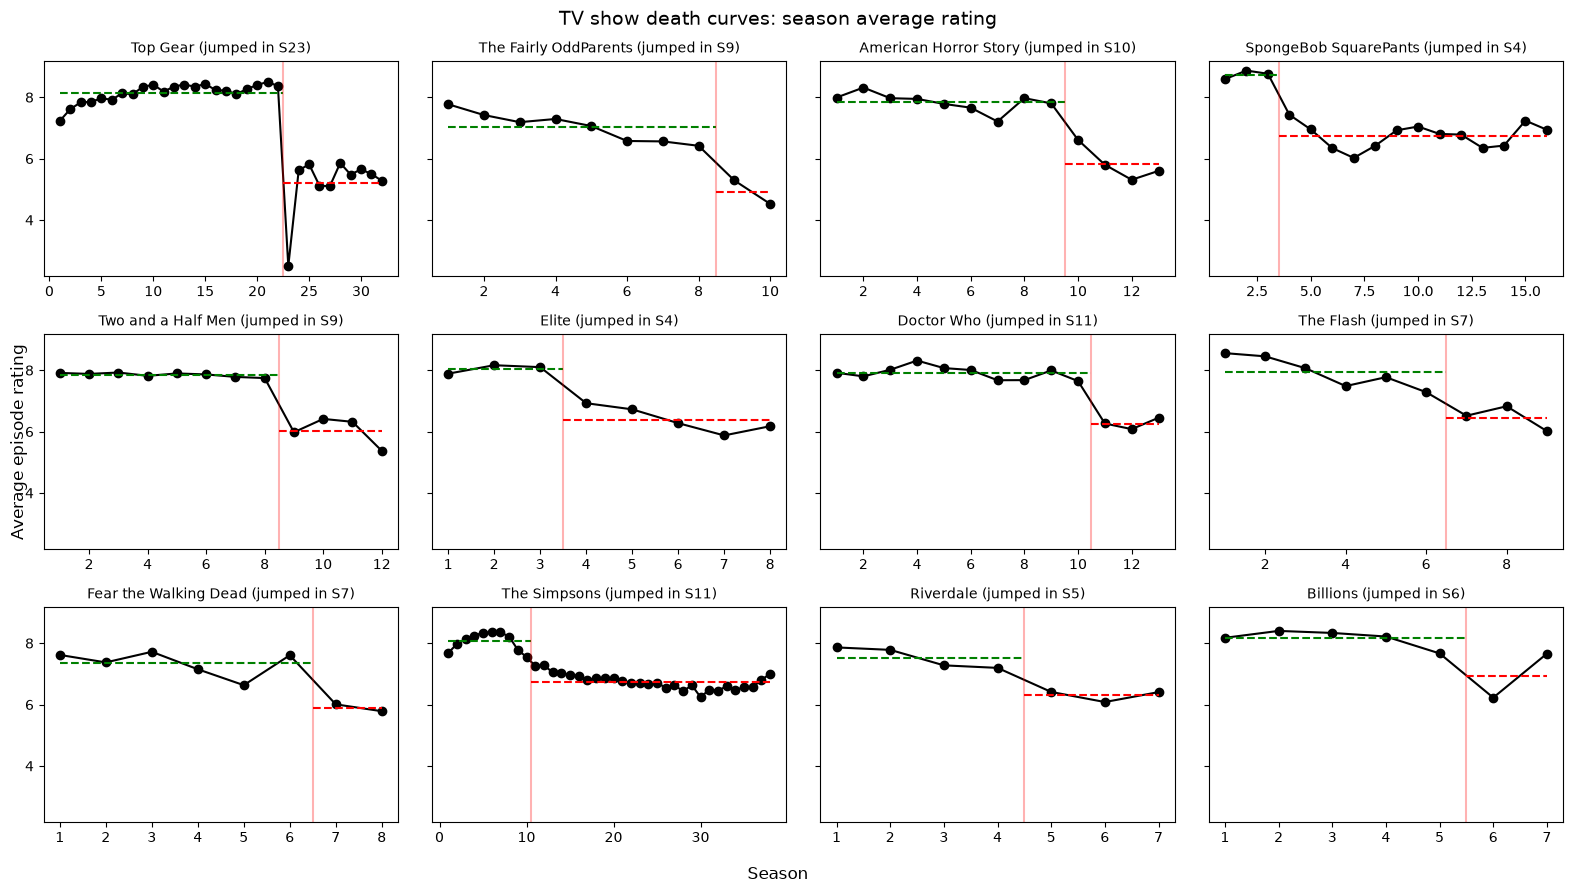

In [12]:
top = jumped.head(12)
fig, axes = plt.subplots(3, 4, figsize=(16, 9), sharey=True)

for ax, (_, row) in zip(axes.flat, top.iterrows()):
    g = seasons_long[seasons_long["showTconst"] == row["showTconst"]].sort_values("seasonNumber")
    s = row["shark_season"]
    ax.plot(g["seasonNumber"], g["avg_rating"], marker="o", color="black")
    ax.hlines(row["before"], g["seasonNumber"].min(), s - 0.5, colors="green", linestyles="--")
    ax.hlines(row["after"], s - 0.5, g["seasonNumber"].max(), colors="red", linestyles="--")
    ax.axvline(s - 0.5, color="red", alpha=0.3)
    ax.set_title(f"{row['showTitle']} (jumped in S{s})", fontsize=10)

fig.suptitle("TV show death curves: season average rating", fontsize=14)
fig.supxlabel("Season")
fig.supylabel("Average episode rating")
fig.tight_layout()
plt.show()

In [13]:
PROCESSED.mkdir(exist_ok=True)
seasons_long.to_parquet(PROCESSED / "tv_seasons.parquet", index=False)
sharks.to_parquet(PROCESSED / "tv_sharks.parquet", index=False)

In [14]:
APP_DATA = Path("../app/data")
seasons_long.to_parquet(APP_DATA / "tv_seasons_app.parquet", index=False)
sharks.to_parquet(APP_DATA / "tv_sharks_app.parquet", index=False)

## Checking the detector on two shows I know
I ran the same steps (5 to 7) on two of my favourite shows to see if the detector agrees with what I expected.

In [15]:
find_show("Game of Thrones")

,showTconst,showTitle,startYear,endYear,showVotes
48177,tt0944947,Game of Thrones,2011,2019,2682171.0
162649,tt2143796,Stupid for Game of Thrones,2012,2012,99.0
330368,tt5779388,Vennori: Lets Play - Game of Thrones,2014,<NA>,27.0
314255,tt4845438,World's Deadliest: Game of Thrones,2014,<NA>,NaN


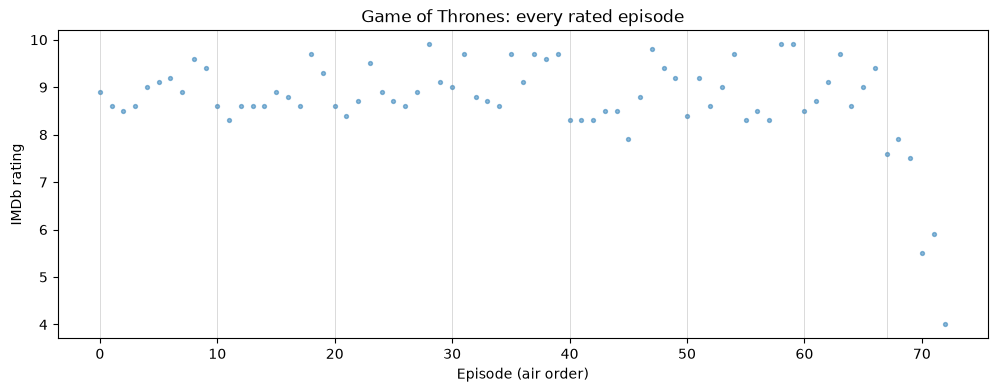

In [16]:
SHOW_ID = "tt0944947"  # paste the ID from find_show if yours differs

one = (
    good[good["showTconst"] == SHOW_ID]
    .sort_values(["seasonNumber", "episodeNumber"])
    .reset_index(drop=True)
)
one["ep_index"] = range(len(one))
title = one["showTitle"].iloc[0]

fig, ax = plt.subplots(figsize=(12, 4))
ax.scatter(one["ep_index"], one["averageRating"], s=8, alpha=0.5)
for i in one.groupby("seasonNumber")["ep_index"].min():
    ax.axvline(i, color="grey", lw=0.5, alpha=0.4)
ax.set(title=f"{title}: every rated episode",
       xlabel="Episode (air order)", ylabel="IMDb rating")
plt.show()

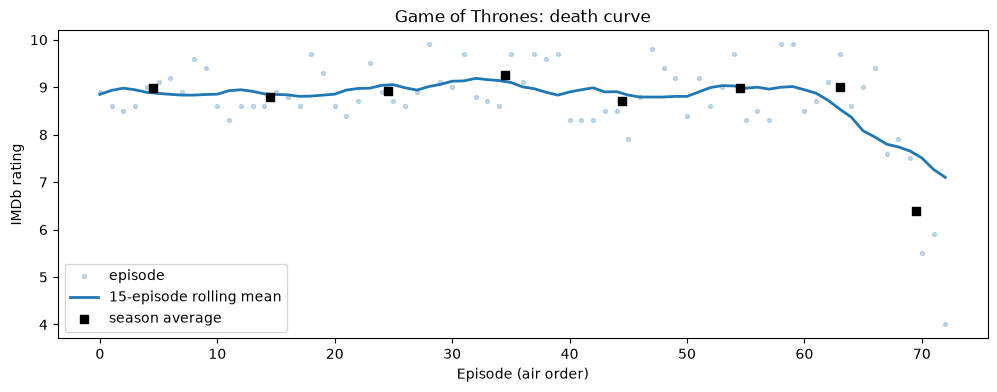

In [17]:
WINDOW = 15
one["smooth"] = (
    one["averageRating"]
    .rolling(window=WINDOW, center=True, min_periods=5)
    .mean()
)
season_avg = one.groupby("seasonNumber").agg(
    mid=("ep_index", "mean"), avg=("averageRating", "mean")
)

fig, ax = plt.subplots(figsize=(12, 4))
ax.scatter(one["ep_index"], one["averageRating"], s=8, alpha=0.25, label="episode")
ax.plot(one["ep_index"], one["smooth"], lw=2, label=f"{WINDOW}-episode rolling mean")
ax.scatter(season_avg["mid"], season_avg["avg"], marker="s", color="black",
           zorder=3, label="season average")
ax.set(title=f"{title}: death curve", xlabel="Episode (air order)", ylabel="IMDb rating")
ax.legend()
plt.show()

In [18]:
g = seasons_long[seasons_long["showTconst"] == SHOW_ID].sort_values("seasonNumber")
res = find_shark(g["avg_rating"])
res["shark_season"] = int(g["seasonNumber"].iloc[res["split"]])
res

{'split': 6,
 'before': 8.94,
 'after': 7.7,
 'drop': 1.24,
 'fit_gain': 0.39,
 'shark_season': 7}

Game of Thrones suddenly went down in the last season, as expected. The detector splits before season 7 (8.94 before, 7.70 after, a drop of 1.24), but the fit gain is only 0.39, below the 0.5 cut-off, so it doesn't count as a clean shark: the seasons bounce around too much. With `min_size=2` it also can't isolate season 8 on its own.

In [19]:
find_show("Friends")

,showTconst,showTitle,startYear,endYear,showVotes
5915,tt0108778,Friends,1994,2004,1214316.0
211306,tt30459041,Your Friends & Neighbors,2025,<NA>,69509.0
79198,tt12074628,Smiling Friends,2020,2026,33621.0
33612,tt0419326,Foster's Home for Imaginary Friends,2004,2009,27396.0
141309,tt1751105,My Little Pony: Friendship Is Magic,2010,2019,26841.0
327155,tt5565334,Friends from College,2017,2019,25177.0
42503,tt0770762,Happy Tree Friends,2001,2026,19463.0
4426,tt0094469,Garfield and Friends,1988,1994,15338.0
78197,tt11997646,Conversations with Friends,2022,2022,10770.0
8379,tt0144701,Barney & Friends,1992,2010,8966.0


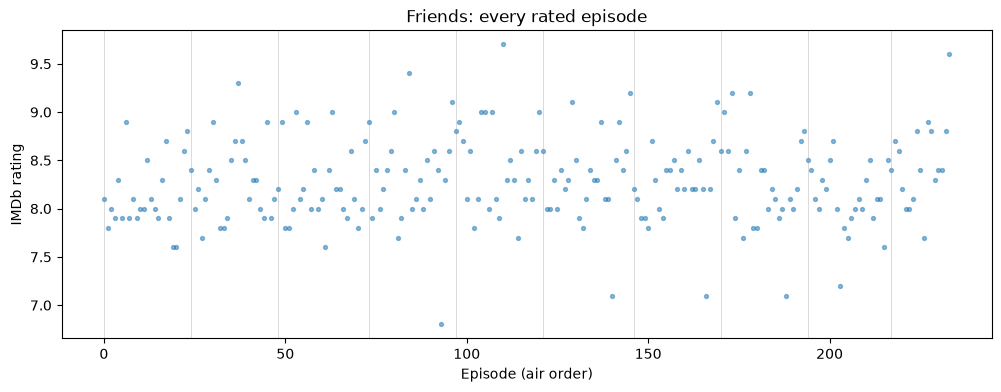

In [20]:
SHOW_ID = "tt0108778"  # paste the ID from find_show if yours differs

one = (
    good[good["showTconst"] == SHOW_ID]
    .sort_values(["seasonNumber", "episodeNumber"])
    .reset_index(drop=True)
)
one["ep_index"] = range(len(one))
title = one["showTitle"].iloc[0]

fig, ax = plt.subplots(figsize=(12, 4))
ax.scatter(one["ep_index"], one["averageRating"], s=8, alpha=0.5)
for i in one.groupby("seasonNumber")["ep_index"].min():
    ax.axvline(i, color="grey", lw=0.5, alpha=0.4)
ax.set(title=f"{title}: every rated episode",
       xlabel="Episode (air order)", ylabel="IMDb rating")
plt.show()

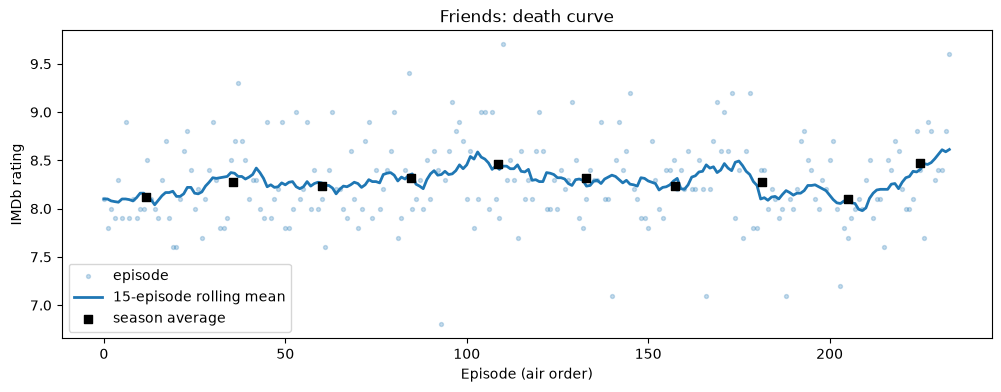

In [21]:
WINDOW = 15
one["smooth"] = (
    one["averageRating"]
    .rolling(window=WINDOW, center=True, min_periods=5)
    .mean()
)
season_avg = one.groupby("seasonNumber").agg(
    mid=("ep_index", "mean"), avg=("averageRating", "mean")
)

fig, ax = plt.subplots(figsize=(12, 4))
ax.scatter(one["ep_index"], one["averageRating"], s=8, alpha=0.25, label="episode")
ax.plot(one["ep_index"], one["smooth"], lw=2, label=f"{WINDOW}-episode rolling mean")
ax.scatter(season_avg["mid"], season_avg["avg"], marker="s", color="black",
           zorder=3, label="season average")
ax.set(title=f"{title}: death curve", xlabel="Episode (air order)", ylabel="IMDb rating")
ax.legend()
plt.show()

In [22]:
g = seasons_long[seasons_long["showTconst"] == SHOW_ID].sort_values("seasonNumber")
res = find_shark(g["avg_rating"])
res["shark_season"] = int(g["seasonNumber"].iloc[res["split"]])
res

{'split': 3,
 'before': 8.21,
 'after': 8.31,
 'drop': -0.1,
 'fit_gain': 0.16,
 'shark_season': 4}

Friends stayed consistent and was slightly better at the end: 8.21 before, 8.31 after, a drop of -0.10 with a fit gain of only 0.16. No shark, as expected.